In [ ]:
%pip install -q kagglehub lightgbm xgboost

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import kagglehub
from pathlib import Path
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

dataset_path = kagglehub.dataset_download("ealaxi/paysim1")

csv_files = list(Path(dataset_path).rglob("*.csv"))

df = pd.read_csv(csv_files[0])

print("Dataset shape:", df.shape)
display(df.head())

Using Colab cache for faster access to the 'paysim1' dataset.
Dataset shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Transactions:")
print(df.duplicated().sum())

print("\nTarget Distribution:")
print(df['isFraud'].value_counts())

print("\nFraud Percentage:")
print(df['isFraud'].value_counts(normalize=True) * 100)

Dataset Shape: (6362620, 11)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB

Missing Values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Duplicate Transactions:
0

Target Distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Fraud Percentage:
isFraud
0    99.87

In [ ]:
fraud_by_type = (
    df.groupby('type')['isFraud']
    .agg(
        total_transactions='count',
        fraud_transactions='sum',
        fraud_rate='mean'
    )
)

fraud_by_type['fraud_rate'] *= 100

fraud_by_type = fraud_by_type.sort_values(
    'fraud_rate',
    ascending=False
)

display(fraud_by_type)

,total_transactions,fraud_transactions,fraud_rate
type,,,
TRANSFER,532909,4097,0.768799
CASH_OUT,2237500,4116,0.183955
CASH_IN,1399284,0,0.000000
DEBIT,41432,0,0.000000
PAYMENT,2151495,0,0.000000


In [ ]:
balance_cols = [
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest'
]

balance_summary = (
    df.groupby('isFraud')[balance_cols]
    .median()
)

display(balance_summary)

,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
isFraud,,,,
0,14069.00,0.0,133311.8,214881.70
1,438983.45,0.0,0.0,4676.42


In [ ]:
zero_balance_analysis = (
    df.assign(
        sender_zero_after=df['newbalanceOrig'].eq(0)
    )
    .groupby('isFraud')['sender_zero_after']
    .agg(['count', 'sum', 'mean'])
)

zero_balance_analysis['mean'] *= 100

display(zero_balance_analysis)

,count,sum,mean
isFraud,,,
0,6354407,3601513,56.677405
1,8213,8053,98.051869


In [ ]:
amount_summary = (
    df.groupby('isFraud')['amount']
    .agg(['count', 'mean', 'median', 'min', 'max'])
)

display(amount_summary)

,count,mean,median,min,max
isFraud,,,,,
0,6354407,1.781970e+05,74684.72,0.01,92445516.64
1,8213,1.467967e+06,441423.44,0.00,10000000.00


In [ ]:
data = df.copy()

print("Original shape:", data.shape)

Original shape: (6362620, 11)


In [ ]:
import numpy as np

data['transaction_hour'] = data['step'] % 24
data['transaction_day'] = data['step'] // 24

data['log_amount'] = np.log1p(data['amount'])

data['amount_to_oldbalance'] = (
    data['amount'] / (data['oldbalanceOrg'] + 1)
)

In [ ]:
data['orig_balance_change'] = (
    data['oldbalanceOrg'] - data['newbalanceOrig']
)

data['dest_balance_change'] = (
    data['newbalanceDest'] - data['oldbalanceDest']
)

data['orig_balance_error'] = (
    data['oldbalanceOrg']
    - data['amount']
    - data['newbalanceOrig']
)

data['dest_balance_error'] = (
    data['oldbalanceDest']
    + data['amount']
    - data['newbalanceDest']
)

data['orig_zero_after'] = (
    data['newbalanceOrig'] == 0
).astype('int8')

data['dest_zero_after'] = (
    data['newbalanceDest'] == 0
).astype('int8')

In [ ]:
data.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,...,transaction_hour,transaction_day,log_amount,amount_to_oldbalance,orig_balance_change,dest_balance_change,orig_balance_error,dest_balance_error,orig_zero_after,dest_zero_after
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,...,1,0,9.194276,0.057834,9839.64,0.0,0.0,9839.64,0,1
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,...,1,0,7.531166,0.087731,1864.28,0.0,0.0,1864.28,0,1
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,...,1,0,5.204007,0.994505,181.00,0.0,0.0,181.00,1,1
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,...,1,0,5.204007,0.994505,181.00,-21182.0,0.0,21363.00,1,1
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,...,1,0,9.364703,0.280788,11668.14,0.0,0.0,11668.14,0,1


In [ ]:
pre_transaction_features = [
    'step',
    'type',
    'amount',
    'oldbalanceOrg',
    'oldbalanceDest',
    'transaction_hour',
    'transaction_day',
    'log_amount',
    'amount_to_oldbalance'
]

balance_inclusive_features = pre_transaction_features + [
    'newbalanceOrig',
    'newbalanceDest',
    'orig_balance_change',
    'dest_balance_change',
    'orig_balance_error',
    'dest_balance_error',
    'orig_zero_after',
    'dest_zero_after'
]

X_pre = pd.get_dummies(
    data[pre_transaction_features],
    columns=['type'],
    dtype='int8'
)

X_full = pd.get_dummies(
    data[balance_inclusive_features],
    columns=['type'],
    dtype='int8'
)

y = data['isFraud'].copy()

print("Pre-transaction features:", X_pre.shape)
print("Balance-inclusive features:", X_full.shape)
print("Target:", y.shape)

Pre-transaction features: (6362620, 13)
Balance-inclusive features: (6362620, 21)
Target: (6362620,)


In [ ]:
for name, features in [
    ('Pre-transaction', X_pre),
    ('Balance-inclusive', X_full)
]:
    print(f"\n{name} feature set")
    print("Shape:", features.shape)
    print("Missing values:", features.isnull().sum().sum())
    print(
        "Infinite values:",
        np.isinf(features.to_numpy()).sum()
    )

print("\nTarget distribution:")
print(y.value_counts())


Pre-transaction feature set
Shape: (6362620, 13)
Missing values: 0
Infinite values: 0

Balance-inclusive feature set
Shape: (6362620, 21)
Missing values: 0
Infinite values: 0

Target distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64


In [ ]:
steps = np.sort(data['step'].unique())

train_cut = steps[int(len(steps) * 0.70)]
val_cut = steps[int(len(steps) * 0.85)]

train_mask = data['step'] < train_cut

val_mask = (
    (data['step'] >= train_cut) &
    (data['step'] < val_cut)
)

test_mask = data['step'] >= val_cut

def split_features(X):
    return (
        X.loc[train_mask].copy(),
        X.loc[val_mask].copy(),
        X.loc[test_mask].copy()
    )

X_pre_train, X_pre_val, X_pre_test = split_features(X_pre)

X_full_train, X_full_val, X_full_test = split_features(X_full)

y_train = y.loc[train_mask]
y_val = y.loc[val_mask]
y_test = y.loc[test_mask]

for name, target in [
    ('Training', y_train),
    ('Validation', y_val),
    ('Testing', y_test)
]:
    print(
        name,
        '| Rows:', len(target),
        '| Fraud:', target.sum(),
        '| Fraud rate:', round(target.mean() * 100, 4), '%'
    )

Training | Rows: 6082007 | Fraud: 5781 | Fraud rate: 0.0951 %
Validation | Rows: 191147 | Fraud: 1180 | Fraud rate: 0.6173 %
Testing | Rows: 89466 | Fraud: 1252 | Fraud rate: 1.3994 %


In [ ]:
# All fraudulent training transactions
fraud_idx = y_train[y_train == 1].index

# Random sample of legitimate transactions
normal_idx = (
    y_train[y_train == 0]
    .sample(n=500000, random_state=42)
    .index
)

sample_idx = fraud_idx.union(normal_idx)

X_lr_train = X_pre_train.loc[sample_idx]
y_lr_train = y_train.loc[sample_idx]

print("Training sample:", X_lr_train.shape)
print(y_lr_train.value_counts())

Training sample: (505781, 13)
isFraud
0    500000
1      5781
Name: count, dtype: int64


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        max_iter=1000,
        solver='lbfgs',
        random_state=42
    ))
])

lr_model.fit(X_lr_train, y_lr_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

lr_val_prob = lr_model.predict_proba(X_pre_val)[:, 1]

lr_val_pred = (lr_val_prob >= 0.5).astype(int)

print("Classification Report:")
print(classification_report(
    y_val,
    lr_val_pred,
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, lr_val_pred))

print("\nROC-AUC:",
      roc_auc_score(y_val, lr_val_prob))

print("PR-AUC:",
      average_precision_score(y_val, lr_val_prob))

Classification Report:
              precision    recall  f1-score   support

           0     0.9966    0.9990    0.9978    189967
           1     0.7289    0.4466    0.5539      1180

    accuracy                         0.9956    191147
   macro avg     0.8627    0.7228    0.7758    191147
weighted avg     0.9949    0.9956    0.9950    191147


Confusion Matrix:
[[189771    196]
 [   653    527]]

ROC-AUC: 0.9755275648678678
PR-AUC: 0.5915949961610402


In [ ]:
import numpy as np
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val, lr_val_prob
)

f1_values = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = np.argmax(f1_values)
best_threshold = thresholds[best_idx]

print("Best threshold:", best_threshold)
print("Best validation F1:", f1_values[best_idx])
print("Precision:", precision[best_idx])
print("Recall:", recall[best_idx])

Best threshold: 0.3693283025392809
Best validation F1: 0.5744878957164509
Precision: 0.637396694214876
Recall: 0.5228813559322034


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=18,
    min_samples_leaf=5,
    max_features='sqrt',
    n_jobs=-1,
    random_state=42
)

rf_model.fit(X_lr_train, y_lr_train)

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

rf_val_prob = rf_model.predict_proba(X_pre_val)[:, 1]

rf_val_pred = (rf_val_prob >= 0.5).astype(int)

print("Classification Report:")
print(classification_report(
    y_val,
    rf_val_pred,
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, rf_val_pred))

print("\nROC-AUC:",
      roc_auc_score(y_val, rf_val_prob))

print("PR-AUC:",
      average_precision_score(y_val, rf_val_prob))

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    0.9998    0.9999    189967
           1     0.9695    0.9975    0.9833      1180

    accuracy                         0.9998    191147
   macro avg     0.9848    0.9986    0.9916    191147
weighted avg     0.9998    0.9998    0.9998    191147


Confusion Matrix:
[[189930     37]
 [     3   1177]]

ROC-AUC: 0.9999968504788477
PR-AUC: 0.9995660970798148


In [ ]:
from sklearn.metrics import precision_recall_curve
import numpy as np

rf_precision, rf_recall, rf_thresholds = (
    precision_recall_curve(y_val, rf_val_prob)
)

rf_f1_values = (
    2 * rf_precision[:-1] * rf_recall[:-1] /
    (rf_precision[:-1] + rf_recall[:-1] + 1e-12)
)

rf_best_idx = np.argmax(rf_f1_values)

rf_best_threshold = rf_thresholds[rf_best_idx]

print("Best threshold:", rf_best_threshold)
print("Best validation F1:", rf_f1_values[rf_best_idx])
print("Precision:", rf_precision[rf_best_idx])
print("Recall:", rf_recall[rf_best_idx])

Best threshold: 0.668996928996929
Best validation F1: 0.997032640949055
Precision: 0.9974554707379135
Recall: 0.9966101694915255


,Feature,Importance
7,amount_to_oldbalance,0.466570
2,oldbalanceOrg,0.118104
6,log_amount,0.082209
1,amount,0.073990
3,oldbalanceDest,0.063386
12,type_TRANSFER,0.056502
4,transaction_hour,0.055353
9,type_CASH_OUT,0.029026
0,step,0.020650
5,transaction_day,0.016452


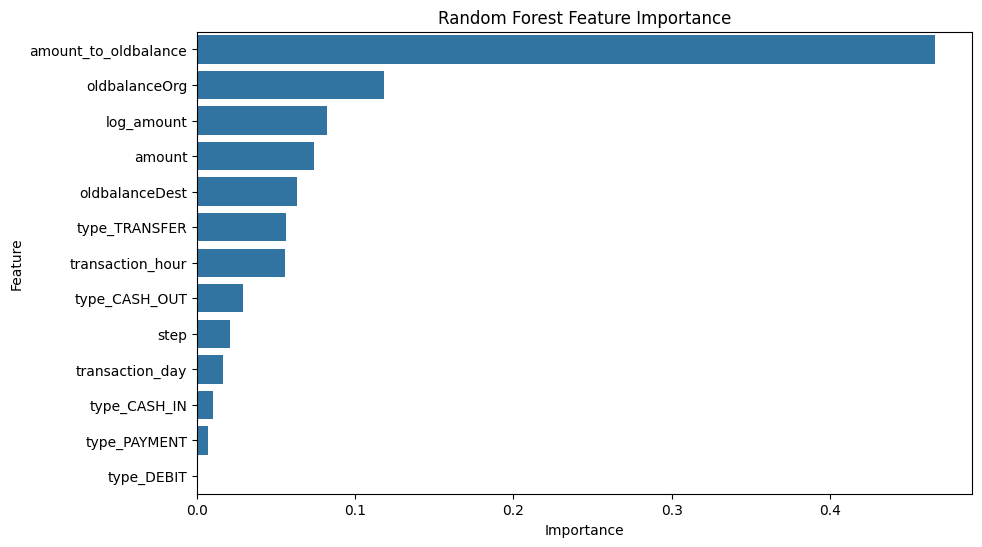

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

feature_importance = pd.DataFrame({
    'Feature': X_lr_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

display(feature_importance)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

rf_test_prob = rf_model.predict_proba(X_pre_test)[:, 1]

rf_test_pred = (
    rf_test_prob >= rf_best_threshold
).astype(int)

print("Test Accuracy:",
      accuracy_score(y_test, rf_test_pred))

print("Test Fraud F1:",
      f1_score(y_test, rf_test_pred))

print("Test ROC-AUC:",
      roc_auc_score(y_test, rf_test_prob))

print("Test PR-AUC:",
      average_precision_score(y_test, rf_test_prob))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_test_pred,
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_test_pred))

Test Accuracy: 0.9998658708336128
Test Fraud F1: 0.9951884522854851
Test ROC-AUC: 0.999990809816181
Test PR-AUC: 0.9994097002291125

Classification Report:
              precision    recall  f1-score   support

           0     0.9999    1.0000    0.9999     88214
           1     0.9992    0.9912    0.9952      1252

    accuracy                         0.9999     89466
   macro avg     0.9995    0.9956    0.9976     89466
weighted avg     0.9999    0.9999    0.9999     89466


Confusion Matrix:
[[88213     1]
 [   11  1241]]


In [ ]:
feature_importance = pd.DataFrame({
    'Feature': X_lr_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

display(feature_importance)

,Feature,Importance
7,amount_to_oldbalance,0.466570
2,oldbalanceOrg,0.118104
6,log_amount,0.082209
1,amount,0.073990
3,oldbalanceDest,0.063386
12,type_TRANSFER,0.056502
4,transaction_hour,0.055353
9,type_CASH_OUT,0.029026
0,step,0.020650
5,transaction_day,0.016452


In [ ]:
features_to_remove = [
    'oldbalanceOrg',
    'amount_to_oldbalance'
]

reduced_columns = [
    col for col in X_lr_train.columns
    if col not in features_to_remove
]

rf_reduced = RandomForestClassifier(
    n_estimators=150,
    max_depth=18,
    min_samples_leaf=5,
    max_features='sqrt',
    n_jobs=-1,
    random_state=42
)

rf_reduced.fit(
    X_lr_train[reduced_columns],
    y_lr_train
)

reduced_prob = rf_reduced.predict_proba(
    X_pre_val[reduced_columns]
)[:, 1]

print("Reduced-feature ROC-AUC:",
      roc_auc_score(y_val, reduced_prob))

print("Reduced-feature PR-AUC:",
      average_precision_score(y_val, reduced_prob))

Reduced-feature ROC-AUC: 0.9711072297748771
Reduced-feature PR-AUC: 0.6138287647788425


In [ ]:
##XGBOOST


from xgboost import XGBClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)
import numpy as np

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=5,
    tree_method='hist',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_lr_train, y_lr_train)

xgb_val_prob = xgb_model.predict_proba(X_pre_val)[:, 1]

print("XGBoost ROC-AUC:",
      roc_auc_score(y_val, xgb_val_prob))

print("XGBoost PR-AUC:",
                      average_precision_score(y_val, xgb_val_prob))

XGBoost ROC-AUC: 0.9999910198497455
XGBoost PR-AUC: 0.9985753063828434


In [ ]:
#### Optimize XGBoost's threshold

xgb_precision, xgb_recall, xgb_thresholds = (
    precision_recall_curve(y_val, xgb_val_prob)
)

xgb_f1 = (
    2 * xgb_precision[:-1] * xgb_recall[:-1] /
    (xgb_precision[:-1] + xgb_recall[:-1] + 1e-12)
)

xgb_best_idx = np.argmax(xgb_f1)
xgb_best_threshold = xgb_thresholds[xgb_best_idx]

print("Best threshold:", xgb_best_threshold)
print("Best F1:", xgb_f1[xgb_best_idx])
print("Precision:", xgb_precision[xgb_best_idx])
print("Recall:", xgb_recall[xgb_best_idx])

Best threshold: 0.9526593
Best F1: 0.9763313609462455
Precision: 0.9738617200674536
Recall: 0.9788135593220338


In [ ]:
### LIGHTGBM


from lightgbm import LGBMClassifier

lgb_model = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=50,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=5,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(X_lr_train, y_lr_train)

lgb_val_prob = lgb_model.predict_proba(X_pre_val)[:, 1]

print("LightGBM ROC-AUC:",
      roc_auc_score(y_val, lgb_val_prob))

print("LightGBM PR-AUC:",
      average_precision_score(y_val, lgb_val_prob))

LightGBM ROC-AUC: 0.9999928890414775
LightGBM PR-AUC: 0.9988691727192457


In [ ]:
### Optimizing LightGBM's threshold


lgb_precision, lgb_recall, lgb_thresholds = (
    precision_recall_curve(y_val, lgb_val_prob)
)

lgb_f1 = (
    2 * lgb_precision[:-1] * lgb_recall[:-1] /
    (lgb_precision[:-1] + lgb_recall[:-1] + 1e-12)
)

lgb_best_idx = np.argmax(lgb_f1)
lgb_best_threshold = lgb_thresholds[lgb_best_idx]

print("Best threshold:", lgb_best_threshold)
print("Best F1:", lgb_f1[lgb_best_idx])
print("Precision:", lgb_precision[lgb_best_idx])
print("Recall:", lgb_recall[lgb_best_idx])

Best threshold: 0.8186156343158701
Best F1: 0.9784411276943592
Precision: 0.9577922077922078
Recall: 1.0


In [ ]:
### Random Forest hyperparameter tuning

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score
import pandas as pd

param_grid = [
    {'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 5},
    {'n_estimators': 150, 'max_depth': 18, 'min_samples_leaf': 5},
    {'n_estimators': 200, 'max_depth': 20, 'min_samples_leaf': 3},
    {'n_estimators': 250, 'max_depth': 25, 'min_samples_leaf': 2}
]

tuning_results = []

for params in param_grid:
    model = RandomForestClassifier(
        **params,
        max_features='sqrt',
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_lr_train, y_lr_train)

    val_prob = model.predict_proba(X_pre_val)[:, 1]

    pr_auc = average_precision_score(y_val, val_prob)

    tuning_results.append({
        **params,
        'PR-AUC': pr_auc
    })

    print(params, "PR-AUC:", pr_auc)

tuning_df = pd.DataFrame(tuning_results)

display(
    tuning_df.sort_values(
        'PR-AUC',
        ascending=False
    )
)

{'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 5} PR-AUC: 0.9996493527222678
{'n_estimators': 150, 'max_depth': 18, 'min_samples_leaf': 5} PR-AUC: 0.9995660970798148
{'n_estimators': 200, 'max_depth': 20, 'min_samples_leaf': 3} PR-AUC: 0.999852971949738
{'n_estimators': 250, 'max_depth': 25, 'min_samples_leaf': 2} PR-AUC: 0.9999295016299199


,n_estimators,max_depth,min_samples_leaf,PR-AUC
3,250,25,2,0.999930
2,200,20,3,0.999853
0,100,12,5,0.999649
1,150,18,5,0.999566


In [34]:
## Selecting the best configuration


best_params = (
    tuning_df.sort_values(
        'PR-AUC',
        ascending=False
    )
    .iloc[0]
)

print("Best configuration:")
print(best_params)

Best configuration:
n_estimators        250.00000
max_depth            25.00000
min_samples_leaf      2.00000
PR-AUC                0.99993
Name: 3, dtype: float64


In [35]:
### Train the best Random Forest

from sklearn.ensemble import RandomForestClassifier

rf_tuned = RandomForestClassifier(
    n_estimators=250,
    max_depth=25,
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

rf_tuned.fit(X_lr_train, y_lr_train)

print("Tuned Random Forest trained successfully!")

Tuned Random Forest trained successfully!


In [36]:
import numpy as np
from sklearn.metrics import (
    precision_recall_curve,
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    average_precision_score
)

rf_tuned_val_prob = rf_tuned.predict_proba(X_pre_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val,
    rf_tuned_val_prob
)

f1_values = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = np.argmax(f1_values)

rf_tuned_threshold = thresholds[best_idx]

rf_tuned_val_pred = (
    rf_tuned_val_prob >= rf_tuned_threshold
).astype(int)

print("Best threshold:", rf_tuned_threshold)

print("Validation accuracy:",
      accuracy_score(y_val, rf_tuned_val_pred))

print("Validation F1:",
      f1_score(y_val, rf_tuned_val_pred))

print("Validation PR-AUC:",
      average_precision_score(y_val, rf_tuned_val_prob))

print("\nClassification Report:")
print(classification_report(
    y_val,
    rf_tuned_val_pred,
    digits=4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, rf_tuned_val_pred))

Best threshold: 0.7187238095238097
Validation accuracy: 0.9999738421215085
Validation F1: 0.9978804578211107
Validation PR-AUC: 0.9999295016299199

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000    189967
           1     0.9983    0.9975    0.9979      1180

    accuracy                         1.0000    191147
   macro avg     0.9991    0.9987    0.9989    191147
weighted avg     1.0000    1.0000    1.0000    191147


Confusion Matrix:
[[189965      2]
 [     3   1177]]


In [38]:
lr_best_threshold = 0.3693283025392809

In [39]:
### Preparing evaluation results for all models

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

models_data = {
    "Logistic Regression": (lr_val_prob, lr_best_threshold),
    "Random Forest": (rf_val_prob, rf_best_threshold),
    "XGBoost": (xgb_val_prob, xgb_best_threshold),
    "LightGBM": (lgb_val_prob, lgb_best_threshold),
    "Tuned Random Forest": (
        rf_tuned_val_prob,
        rf_tuned_threshold
    )
}

results = []

for name, (probs, threshold) in models_data.items():

    preds = (probs >= threshold).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, preds),
        "Precision": precision_score(y_val, preds),
        "Recall": recall_score(y_val, preds),
        "F1-score": f1_score(y_val, preds),
        "ROC-AUC": roc_auc_score(y_val, probs),
        "PR-AUC": average_precision_score(y_val, probs)
    })

results_df = pd.DataFrame(results)

display(results_df.round(5))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.99522,0.63740,0.52288,0.57449,0.97553,0.59159
1,Random Forest,0.99996,0.99746,0.99661,0.99703,1.00000,0.99957
2,XGBoost,0.99971,0.97386,0.97881,0.97633,0.99999,0.99858
3,LightGBM,0.99973,0.95779,1.00000,0.97844,0.99999,0.99887
4,Tuned Random Forest,0.99997,0.99830,0.99746,0.99788,1.00000,0.99993


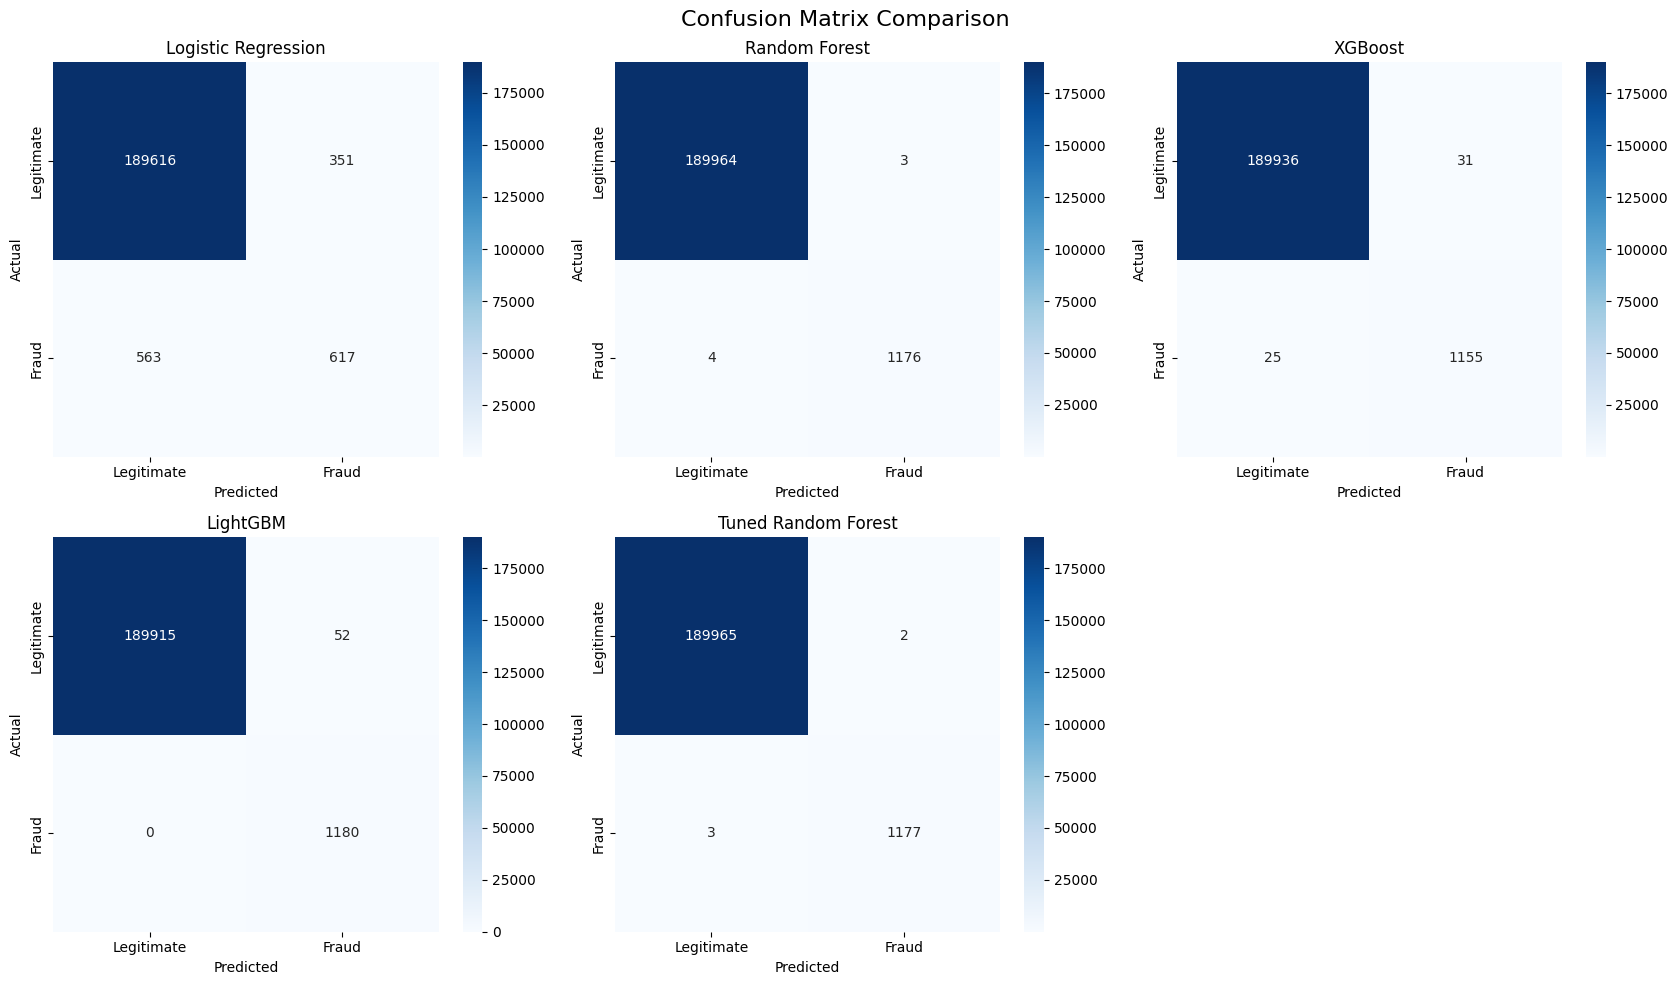

In [40]:
### Confusion matrix heatmaps

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

axes = axes.flatten()

for i, (name, (probs, threshold)) in enumerate(models_data.items()):

    preds = (probs >= threshold).astype(int)

    cm = confusion_matrix(y_val, preds)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"],
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

for j in range(len(models_data), len(axes)):
    axes[j].axis("off")

plt.suptitle("Confusion Matrix Comparison", fontsize=16)
plt.tight_layout()
plt.show()

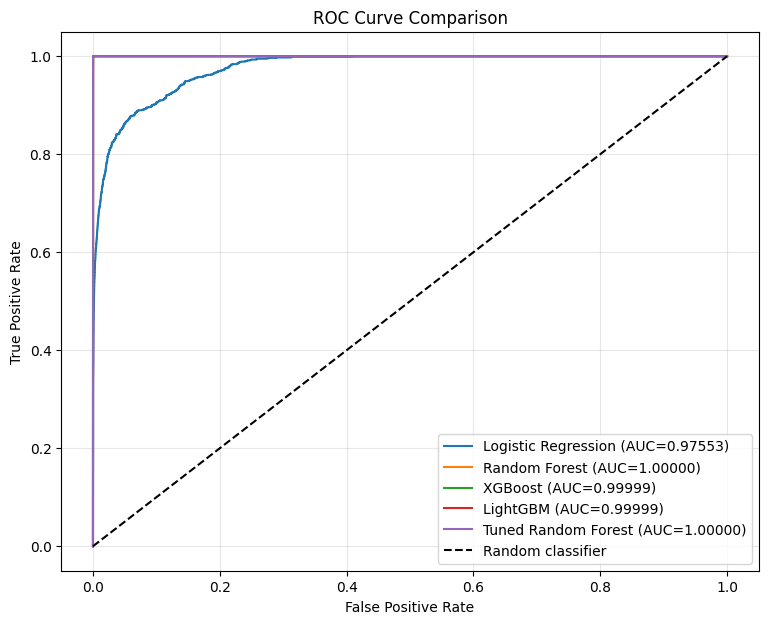

In [42]:
### ROC curve comparison


plt.figure(figsize=(9, 7))

for name, (probs, threshold) in models_data.items():

    fpr, tpr, _ = roc_curve(y_val, probs)

    auc_score = roc_auc_score(y_val, probs)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc_score:.5f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

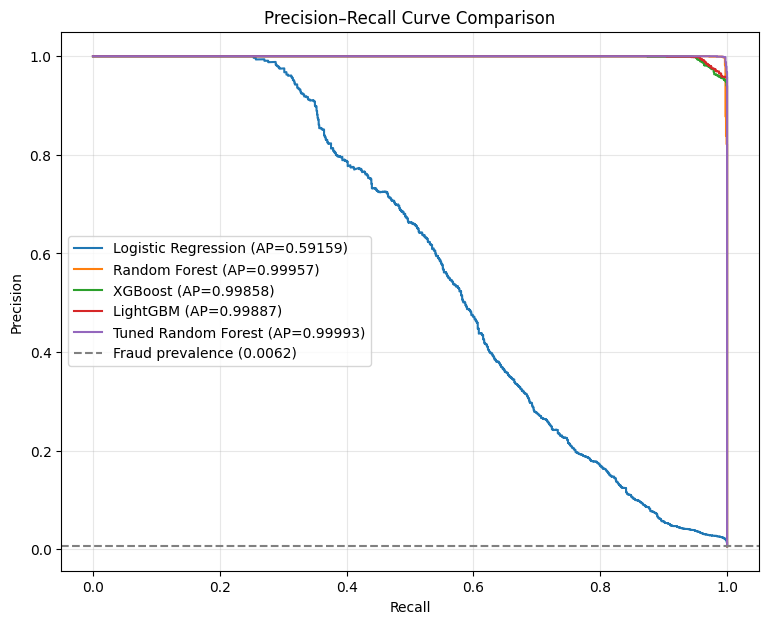

In [43]:
#### Precision–Recall curve comparison


plt.figure(figsize=(9, 7))

for name, (probs, threshold) in models_data.items():

    precision, recall, _ = precision_recall_curve(
        y_val, probs
    )

    pr_auc = average_precision_score(y_val, probs)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP={pr_auc:.5f})"
    )

baseline = y_val.mean()

plt.axhline(
    baseline,
    linestyle="--",
    color="gray",
    label=f"Fraud prevalence ({baseline:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

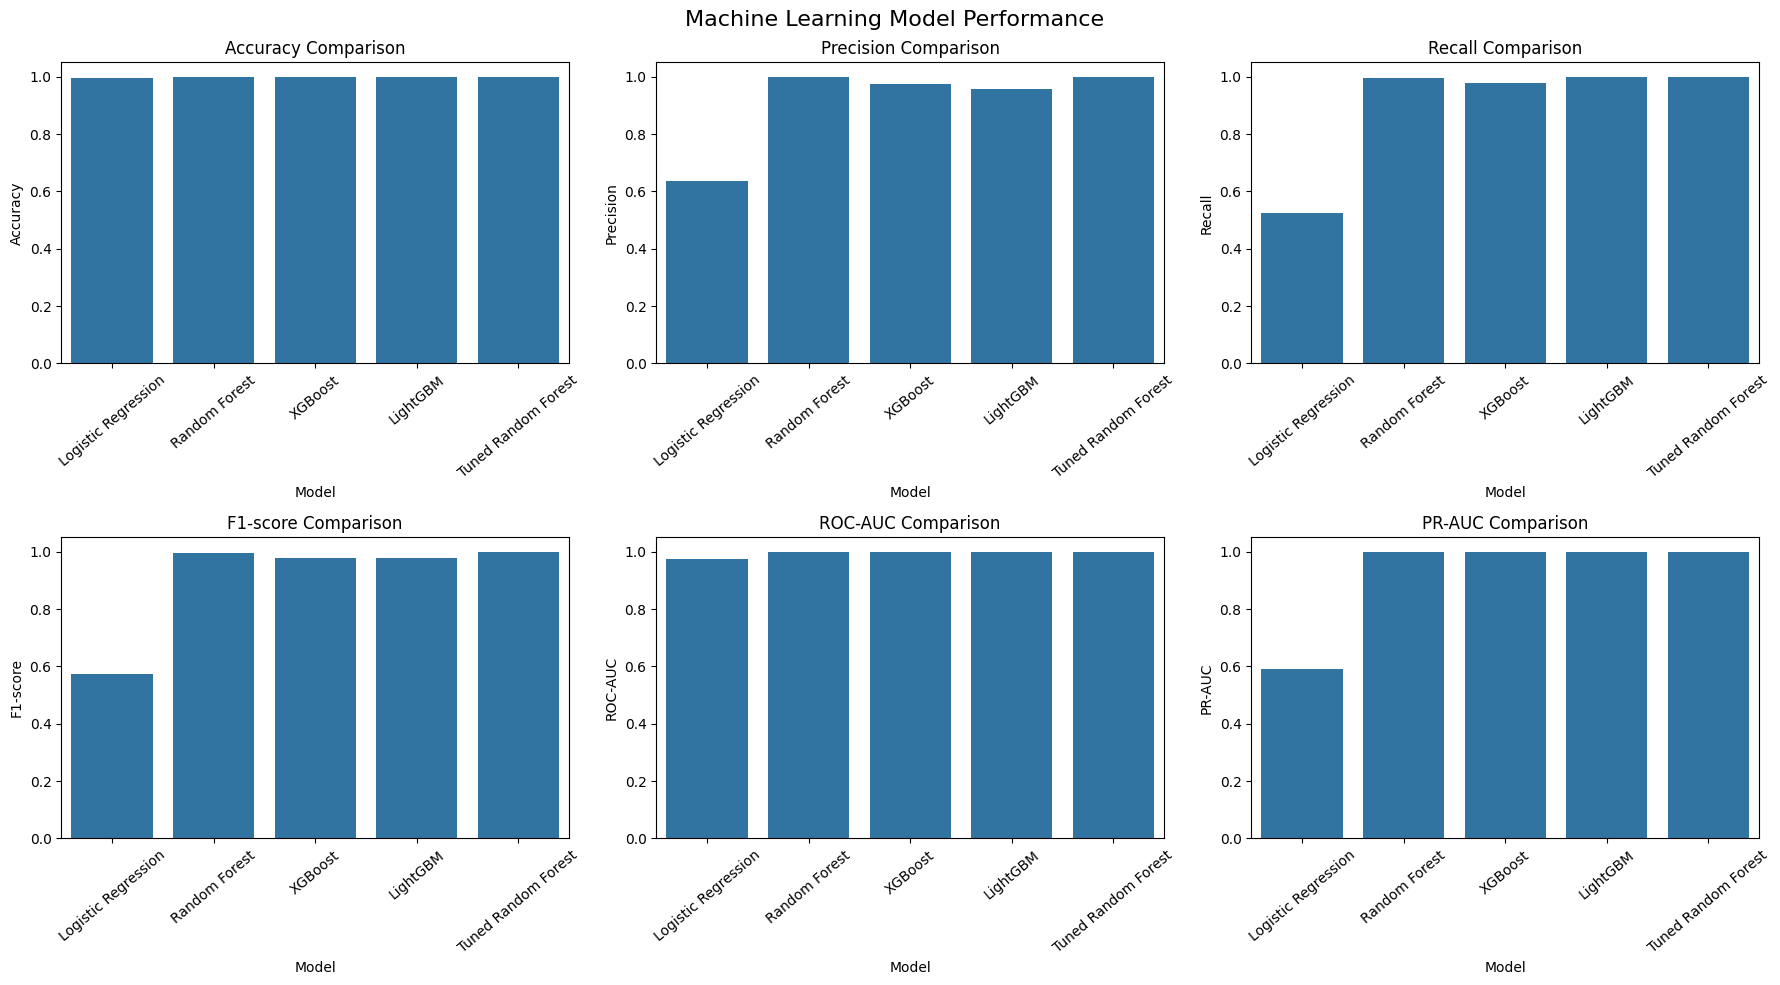

In [44]:
### Model comparison bar charts


metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "PR-AUC"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, metric in zip(axes.flatten(), metrics):

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric,
        ax=ax
    )

    ax.set_title(f"{metric} Comparison")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=40)

plt.suptitle("Machine Learning Model Performance", fontsize=16)
plt.tight_layout()
plt.show()

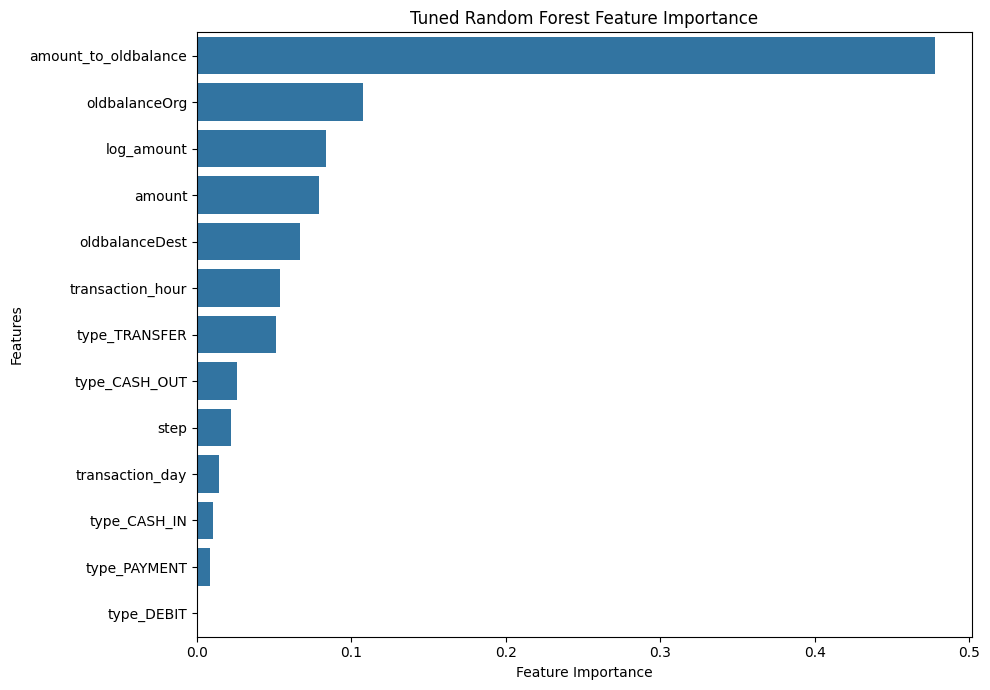

In [45]:
#### Tuned Random Forest feature importance

importance_df = pd.DataFrame({
    "Feature": X_lr_train.columns,
    "Importance": rf_tuned.feature_importances_
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Tuned Random Forest Feature Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

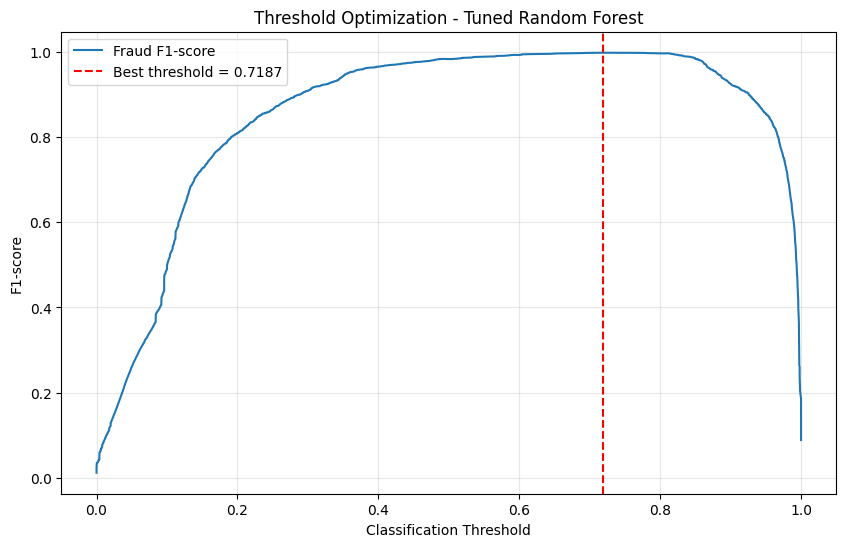

In [46]:
#### Threshold vs F1-score

precision, recall, thresholds = precision_recall_curve(
    y_val,
    rf_tuned_val_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-12)
)

plt.figure(figsize=(10, 6))

plt.plot(
    thresholds,
    f1_scores,
    label="Fraud F1-score"
)

plt.axvline(
    rf_tuned_threshold,
    color="red",
    linestyle="--",
    label=f"Best threshold = {rf_tuned_threshold:.4f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("F1-score")
plt.title("Threshold Optimization - Tuned Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

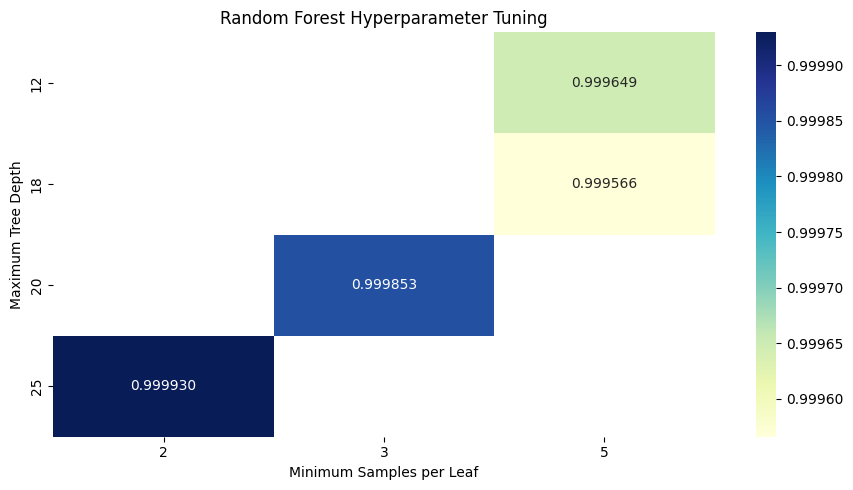

In [47]:
### Hyperparameter tuning heatmap

tuning_heatmap = tuning_df.pivot(
    index="max_depth",
    columns="min_samples_leaf",
    values="PR-AUC"
)

plt.figure(figsize=(9, 5))

sns.heatmap(
    tuning_heatmap,
    annot=True,
    fmt=".6f",
    cmap="YlGnBu"
)

plt.title("Random Forest Hyperparameter Tuning")
plt.xlabel("Minimum Samples per Leaf")
plt.ylabel("Maximum Tree Depth")
plt.tight_layout()
plt.show()

In [48]:
### save the model

import joblib

joblib.dump({
    "model": rf_tuned,
    "threshold": float(rf_tuned_threshold),
    "features": X_lr_train.columns.tolist()
}, "fraud_detection_rf_tuned.pkl", compress=3)

print("Model saved successfully!")

Model saved successfully!


In [49]:
## downloading the file

from google.colab import files

files.download("fraud_detection_rf_tuned.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [50]:
### Analyzing the sender-balance relationship

import numpy as np
import pandas as pd

analysis_df = df[[
    "type",
    "amount",
    "oldbalanceOrg",
    "isFraud"
]].copy()

analysis_df["balance_ratio"] = (
    analysis_df["amount"] /
    (analysis_df["oldbalanceOrg"] + 1)
)

analysis_df["full_balance_transfer"] = (
    np.isclose(
        analysis_df["amount"],
        analysis_df["oldbalanceOrg"],
        rtol=0,
        atol=0.01
    )
    & (analysis_df["oldbalanceOrg"] > 0)
)

summary = analysis_df.groupby("isFraud").agg(
    total_transactions=("isFraud", "size"),
    median_balance_ratio=("balance_ratio", "median"),
    full_balance_transfer_rate=(
        "full_balance_transfer", "mean"
    )
)

summary["full_balance_transfer_rate"] *= 100

display(summary.round(4))

,total_transactions,median_balance_ratio,full_balance_transfer_rate
isFraud,,,
0,6354407,6.5116,0.0000
1,8213,1.0000,97.6257


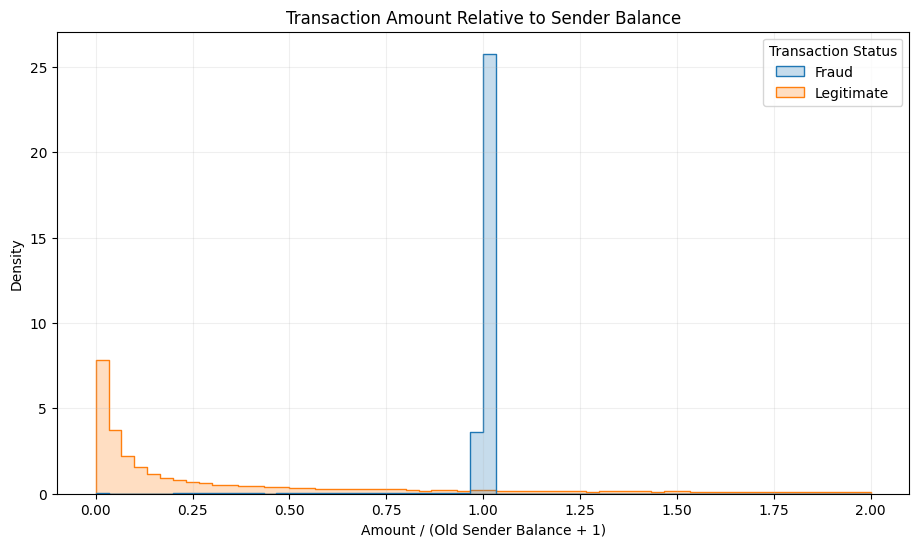

In [51]:
### Visualizing the relationship

import matplotlib.pyplot as plt
import seaborn as sns

fraud_data = analysis_df[
    analysis_df["isFraud"] == 1
]

normal_data = analysis_df[
    analysis_df["isFraud"] == 0
].sample(
    n=50000,
    random_state=42
)

plot_df = pd.concat([
    fraud_data,
    normal_data
])

plot_df = plot_df[
    plot_df["balance_ratio"].between(0, 2)
].copy()

plot_df["Transaction Status"] = (
    plot_df["isFraud"].map({
        0: "Legitimate",
        1: "Fraud"
    })
)

plt.figure(figsize=(11, 6))

sns.histplot(
    data=plot_df,
    x="balance_ratio",
    hue="Transaction Status",
    bins=60,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Transaction Amount Relative to Sender Balance")
plt.xlabel("Amount / (Old Sender Balance + 1)")
plt.ylabel("Density")
plt.grid(alpha=0.2)
plt.show()

In [52]:
### Fraud rate by full-balance transfer

pattern_summary = analysis_df.groupby(
    "full_balance_transfer"
).agg(
    total_transactions=("isFraud", "size"),
    fraud_transactions=("isFraud", "sum"),
    fraud_rate=("isFraud", "mean")
)

pattern_summary["fraud_rate"] *= 100

display(pattern_summary.round(4))

,total_transactions,fraud_transactions,fraud_rate
full_balance_transfer,,,
False,6354601,195,0.0031
True,8019,8018,99.9875


In [53]:
#### Checking whether the pattern differs by transaction type

type_pattern = analysis_df.groupby(
    ["type", "full_balance_transfer"]
).agg(
    transactions=("isFraud", "size"),
    fraud_count=("isFraud", "sum"),
    fraud_rate=("isFraud", "mean")
).reset_index()

type_pattern["fraud_rate"] *= 100

display(type_pattern.round(4))

,type,full_balance_transfer,transactions,fraud_count,fraud_rate
0,CASH_IN,False,1399284,0,0.0000
1,CASH_OUT,False,2233425,41,0.0018
2,CASH_OUT,True,4075,4075,100.0000
3,DEBIT,False,41432,0,0.0000
4,PAYMENT,False,2151494,0,0.0000
5,PAYMENT,True,1,0,0.0000
6,TRANSFER,False,528966,154,0.0291
7,TRANSFER,True,3943,3943,100.0000


In [54]:
### Testing some synthetic transactions

import pandas as pd
import numpy as np
import joblib

# Load saved model
package = joblib.load("fraud_detection_rf_tuned.pkl")

model = package["model"]
threshold = package["threshold"]
feature_columns = package["features"]

# Create 5 synthetic transactions
transactions = pd.DataFrame([
    {
        "step": 500,
        "type": "PAYMENT",
        "amount": 500,
        "oldbalanceOrg": 20000,
        "oldbalanceDest": 10000
    },
    {
        "step": 501,
        "type": "TRANSFER",
        "amount": 50000,
        "oldbalanceOrg": 50000,
        "oldbalanceDest": 0
    },
    {
        "step": 502,
        "type": "CASH_OUT",
        "amount": 15000,
        "oldbalanceOrg": 15000,
        "oldbalanceDest": 5000
    },
    {
        "step": 503,
        "type": "TRANSFER",
        "amount": 2000,
        "oldbalanceOrg": 100000,
        "oldbalanceDest": 50000
    },
    {
        "step": 504,
        "type": "CASH_IN",
        "amount": 1000,
        "oldbalanceOrg": 5000,
        "oldbalanceDest": 20000
    }
])

# Apply the same feature engineering
transactions["transaction_hour"] = transactions["step"] % 24
transactions["transaction_day"] = transactions["step"] // 24

transactions["log_amount"] = np.log1p(
    transactions["amount"]
)

transactions["amount_to_oldbalance"] = (
    transactions["amount"] /
    (transactions["oldbalanceOrg"] + 1)
)

# One-hot encoding
X_new = pd.get_dummies(
    transactions,
    columns=["type"],
    dtype="int8"
)

# Match the exact training features and their order
X_new = X_new.reindex(
    columns=feature_columns,
    fill_value=0
)

# Predict fraud probabilities
fraud_probabilities = model.predict_proba(X_new)[:, 1]

predictions = (
    fraud_probabilities >= threshold
).astype(int)

# Display results
results = transactions[
    ["type", "amount", "oldbalanceOrg", "oldbalanceDest"]
].copy()

results["Fraud Probability"] = fraud_probabilities.round(4)

results["Prediction"] = np.where(
    predictions == 1,
    "Fraudulent",
    "Legitimate"
)

display(results)

,type,amount,oldbalanceOrg,oldbalanceDest,Fraud Probability,Prediction
0,PAYMENT,500,20000,10000,0.0000,Legitimate
1,TRANSFER,50000,50000,0,0.9748,Fraudulent
2,CASH_OUT,15000,15000,5000,0.8070,Fraudulent
3,TRANSFER,2000,100000,50000,0.0768,Legitimate
4,CASH_IN,1000,5000,20000,0.0777,Legitimate


In [55]:
### Reusable fraud prediction function

def predict_fraud(transactions, model_package):
    data = transactions.copy()

    data["transaction_hour"] = data["step"] % 24
    data["transaction_day"] = data["step"] // 24
    data["log_amount"] = np.log1p(data["amount"])

    data["amount_to_oldbalance"] = (
        data["amount"] / (data["oldbalanceOrg"] + 1)
    )

    X = pd.get_dummies(
        data,
        columns=["type"],
        dtype="int8"
    )

    X = X.reindex(
        columns=model_package["features"],
        fill_value=0
    )

    scores = model_package["model"].predict_proba(X)[:, 1]

    result = transactions.copy()
    result["Fraud Score"] = scores
    result["Prediction"] = np.where(
        scores >= model_package["threshold"],
        "Fraudulent",
        "Legitimate"
    )

    return result


predictions_df = predict_fraud(transactions, package)

display(predictions_df)

,step,type,amount,oldbalanceOrg,oldbalanceDest,transaction_hour,transaction_day,log_amount,amount_to_oldbalance,Fraud Score,Prediction
0,500,PAYMENT,500,20000,10000,20,20,6.216606,0.024999,0.000000,Legitimate
1,501,TRANSFER,50000,50000,0,21,20,10.819798,0.999980,0.974834,Fraudulent
2,502,CASH_OUT,15000,15000,5000,22,20,9.615872,0.999933,0.806990,Fraudulent
3,503,TRANSFER,2000,100000,50000,23,20,7.601402,0.020000,0.076762,Legitimate
4,504,CASH_IN,1000,5000,20000,0,21,6.908755,0.199960,0.077667,Legitimate


In [56]:
### Analyzing the relationship


import pandas as pd
import numpy as np

analysis_df = df[
    ["type", "amount", "oldbalanceOrg", "isFraud"]
].copy()

analysis_df["balance_ratio"] = (
    analysis_df["amount"] /
    (analysis_df["oldbalanceOrg"] + 1)
)

analysis_df["full_balance_transfer"] = (
    np.isclose(
        analysis_df["amount"],
        analysis_df["oldbalanceOrg"],
        rtol=0,
        atol=0.01
    )
    & (analysis_df["oldbalanceOrg"] > 0)
)

summary = analysis_df.groupby("isFraud").agg(
    total_transactions=("isFraud", "size"),
    median_balance_ratio=("balance_ratio", "median"),
    full_balance_transfer_rate=(
        "full_balance_transfer", "mean"
    )
)

summary["full_balance_transfer_rate"] *= 100

display(summary.round(4))

,total_transactions,median_balance_ratio,full_balance_transfer_rate
isFraud,,,
0,6354407,6.5116,0.0000
1,8213,1.0000,97.6257


In [57]:
pattern_summary = analysis_df.groupby(
    "full_balance_transfer"
).agg(
    total_transactions=("isFraud", "size"),
    fraud_transactions=("isFraud", "sum"),
    fraud_rate=("isFraud", "mean")
)

pattern_summary["fraud_rate"] *= 100

display(pattern_summary.round(4))

,total_transactions,fraud_transactions,fraud_rate
full_balance_transfer,,,
False,6354601,195,0.0031
True,8019,8018,99.9875


,type,full_balance_transfer,transactions,fraud_count,fraud_rate
0,CASH_IN,False,1399284,0,0.0000
1,CASH_OUT,False,2233425,41,0.0018
2,CASH_OUT,True,4075,4075,100.0000
3,DEBIT,False,41432,0,0.0000
4,PAYMENT,False,2151494,0,0.0000
5,PAYMENT,True,1,0,0.0000
6,TRANSFER,False,528966,154,0.0291
7,TRANSFER,True,3943,3943,100.0000


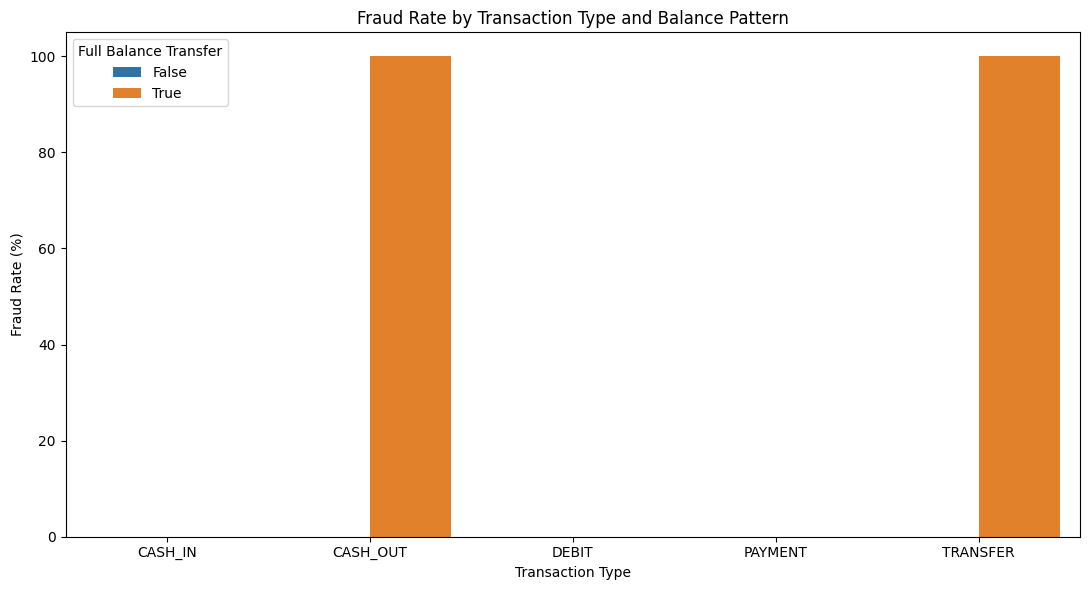

In [58]:
### Visualize fraud rates by transaction type

import matplotlib.pyplot as plt
import seaborn as sns

type_pattern = analysis_df.groupby(
    ["type", "full_balance_transfer"]
).agg(
    transactions=("isFraud", "size"),
    fraud_count=("isFraud", "sum"),
    fraud_rate=("isFraud", "mean")
).reset_index()

type_pattern["fraud_rate"] *= 100

display(type_pattern.round(4))

plt.figure(figsize=(11, 6))

sns.barplot(
    data=type_pattern,
    x="type",
    y="fraud_rate",
    hue="full_balance_transfer"
)

plt.title("Fraud Rate by Transaction Type and Balance Pattern")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.legend(title="Full Balance Transfer")
plt.tight_layout()
plt.show()



In [59]:
#### Rule-based fraud detector



from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

val_data = df.loc[y_val.index]

rule_predictions = (
    val_data["type"].isin(["TRANSFER", "CASH_OUT"])
    & (val_data["oldbalanceOrg"] > 0)
    & np.isclose(
        val_data["amount"],
        val_data["oldbalanceOrg"],
        rtol=0,
        atol=0.01
    )
).astype(int)

print("Rule-based Classification Report:")
print(classification_report(
    y_val,
    rule_predictions,
    digits=4,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_val, rule_predictions))

print("Fraud F1:",
      f1_score(y_val, rule_predictions))

Rule-based Classification Report:
              precision    recall  f1-score   support

           0     0.9999    1.0000    0.9999    189967
           1     1.0000    0.9839    0.9919      1180

    accuracy                         0.9999    191147
   macro avg     0.9999    0.9919    0.9959    191147
weighted avg     0.9999    0.9999    0.9999    191147

Confusion Matrix:
[[189967      0]
 [    19   1161]]
Fraud F1: 0.9918838103374626


In [60]:
#### Compare the rule with Random Forest

rule_comparison = pd.DataFrame({
    "Model": [
        "Rule-based detector",
        "Tuned Random Forest"
    ],
    "Precision": [
        precision_score(y_val, rule_predictions),
        precision_score(y_val, rf_tuned_val_pred)
    ],
    "Recall": [
        recall_score(y_val, rule_predictions),
        recall_score(y_val, rf_tuned_val_pred)
    ],
    "F1-score": [
        f1_score(y_val, rule_predictions),
        f1_score(y_val, rf_tuned_val_pred)
    ]
})

display(rule_comparison.round(5))

,Model,Precision,Recall,F1-score
0,Rule-based detector,1.0000,0.98390,0.99188
1,Tuned Random Forest,0.9983,0.99746,0.99788


In [61]:
### Evaluate non-full-balance transactions

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

val_data = df.loc[y_val.index]

full_balance = (
    val_data["type"].isin(["TRANSFER", "CASH_OUT"])
    & (val_data["oldbalanceOrg"] > 0)
    & np.isclose(
        val_data["amount"],
        val_data["oldbalanceOrg"],
        rtol=0,
        atol=0.01
    )
)

non_full_mask = ~full_balance

y_non_full = y_val.loc[non_full_mask]
pred_non_full = rf_tuned_val_pred[non_full_mask.to_numpy()]

print("Transactions:", len(y_non_full))
print("Fraud cases:", y_non_full.sum())

print("\nClassification Report:")
print(classification_report(
    y_non_full,
    pred_non_full,
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_non_full,
    pred_non_full
))

print("\nFraud Recall:",
      recall_score(y_non_full, pred_non_full))

Transactions: 189986
Fraud cases: 19

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000    189967
           1     0.8889    0.8421    0.8649        19

    accuracy                         1.0000    189986
   macro avg     0.9444    0.9210    0.9324    189986
weighted avg     1.0000    1.0000    1.0000    189986


Confusion Matrix:
[[189965      2]
 [     3     16]]

Fraud Recall: 0.8421052631578947


In [62]:
#### Inspect the missed fraud cases

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

val_data = df.loc[y_val.index]

full_balance = (
    val_data["type"].isin(["TRANSFER", "CASH_OUT"])
    & (val_data["oldbalanceOrg"] > 0)
    & np.isclose(
        val_data["amount"],
        val_data["oldbalanceOrg"],
        rtol=0,
        atol=0.01
    )
)

non_full_mask = ~full_balance

y_non_full = y_val.loc[non_full_mask]
pred_non_full = rf_tuned_val_pred[non_full_mask.to_numpy()]

print("Transactions:", len(y_non_full))
print("Fraud cases:", y_non_full.sum())

print("\nClassification Report:")
print(classification_report(
    y_non_full,
    pred_non_full,
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_non_full,
    pred_non_full
))

print("\nFraud Recall:",
      recall_score(y_non_full, pred_non_full))

Transactions: 189986
Fraud cases: 19

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000    189967
           1     0.8889    0.8421    0.8649        19

    accuracy                         1.0000    189986
   macro avg     0.9444    0.9210    0.9324    189986
weighted avg     1.0000    1.0000    1.0000    189986


Confusion Matrix:
[[189965      2]
 [     3     16]]

Fraud Recall: 0.8421052631578947


## Fraud Detection & Risk Assessment — Final Project Summary

### 1. Project Objective

Develop a machine learning-based fraud detection system to identify potentially fraudulent financial transactions using historical transaction characteristics.

### 2. Dataset

- **Dataset:** PaySim Synthetic Financial Transactions
- **Total transactions:** 6,362,620
- **Fraudulent transactions:** 8,213
- **Legitimate transactions:** 6,354,407
- **Fraud prevalence:** Approximately 0.129%

The dataset is highly imbalanced, making fraud-class precision, recall, F1-score, and Average Precision particularly important evaluation metrics.

### 3. Methodology

- Performed exploratory data analysis to investigate transaction distributions and fraud patterns.
- Engineered features including transaction hour, transaction day, log-transformed amount, and amount-to-sender-balance ratio.
- Used a chronological training, validation, and testing split.
- Trained Logistic Regression, Random Forest, XGBoost, and LightGBM.
- Compared models using precision, recall, F1-score, ROC-AUC, and Average Precision.
- Performed Random Forest hyperparameter tuning and validation-based classification threshold optimization.
- Saved the tuned Random Forest model and implemented a reusable prediction function.

### 4. Model Comparison

| Model | Validation Fraud F1-score |
|---|---:|
| Logistic Regression | 0.5745 |
| Random Forest | 0.9970 |
| XGBoost | 0.9763 |
| LightGBM | 0.9784 |
| Tuned Random Forest | **0.9979** |

The tuned Random Forest was the best-performing model on the validation dataset.

Its selected hyperparameters were:

- Number of trees: 250
- Maximum tree depth: 25
- Minimum samples per leaf: 2
- Classification threshold: approximately 0.7187

### 5. Robustness Analysis

Further analysis identified a highly predictive pattern in the synthetic dataset:

- Approximately 97.63% of fraudulent transactions involved transferring the sender's entire available balance.
- A rule-based detector using this relationship achieved a validation fraud F1-score of approximately 0.9919.
- The tuned Random Forest achieved a validation F1-score of approximately 0.9979.
- On transactions that did not match the full-balance pattern, the tuned model detected 16 of 19 fraudulent transactions, achieving 84.21% recall and an F1-score of approximately 0.8649.

These results indicate that the near-perfect overall performance is strongly influenced by the dataset's synthetic transaction-generation patterns.

### 6. Limitations

- PaySim is synthetic and may not represent real-world banking behavior.
- The sender-balance relationship is unusually predictive in this dataset.
- The difficult non-full-balance subset contains relatively few fraudulent examples.
- The model's predicted scores have not been calibrated as real-world fraud probabilities.
- Additional external validation would be required before considering production deployment.

### 7. Business Recommendations

- Use fraud-risk scores to prioritize suspicious transactions for further review.
- Evaluate the trade-off between missed fraud and false alarms when selecting decision thresholds.
- Monitor model performance and fraud prevalence over time.
- Combine machine learning with domain-specific fraud rules and human investigation.
- Validate the system using representative real-world data before deployment.

### 8. Conclusion

The project demonstrated an end-to-end fraud detection workflow, including data analysis, feature engineering, machine learning, hyperparameter tuning, model evaluation, and inference.

The tuned Random Forest achieved a validation fraud F1-score of approximately 0.9979 on PaySim. Additional robustness experiments showed that much of this performance was associated with a strong synthetic-data pattern.

The project highlights both the effectiveness of ensemble models for structured transaction data and the importance of critically examining unusually high machine learning performance.

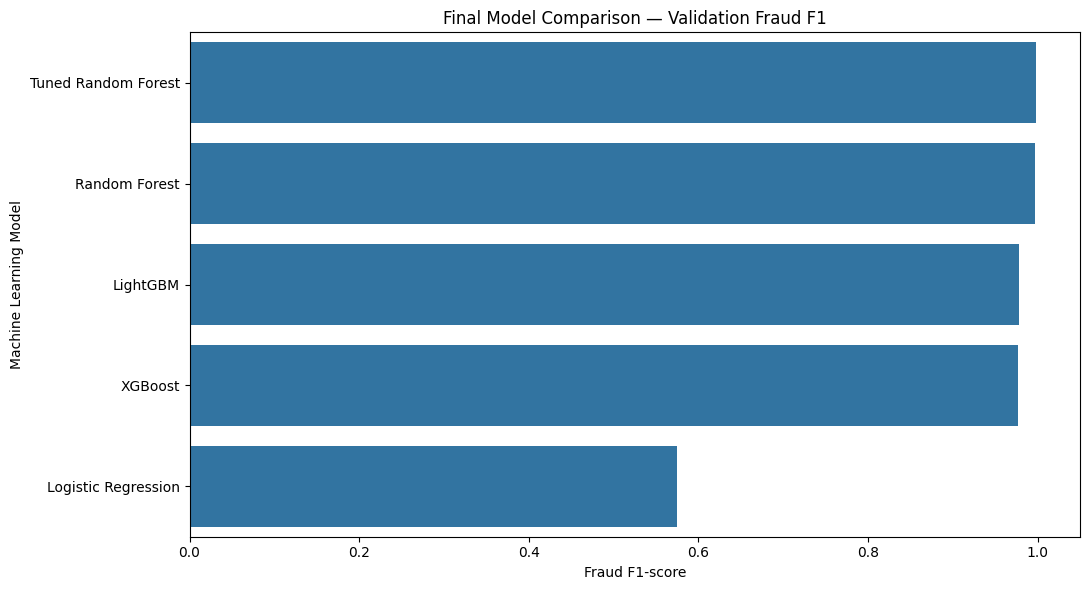

In [63]:
### final results visualization

import matplotlib.pyplot as plt
import seaborn as sns

final_scores = results_df.sort_values(
    "F1-score",
    ascending=False
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=final_scores,
    x="F1-score",
    y="Model"
)

plt.title("Final Model Comparison — Validation Fraud F1")
plt.xlabel("Fraud F1-score")
plt.ylabel("Machine Learning Model")
plt.xlim(0, 1.05)

plt.tight_layout()
plt.show()